In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
import json
import os


#### 1. Evaluation of the number of demos. Draw figure for the final results.

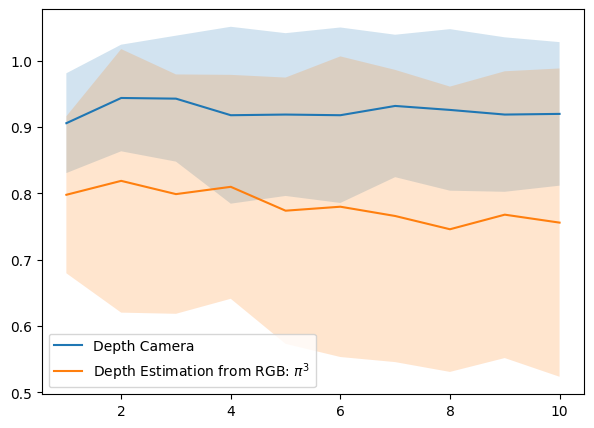

In [2]:
# Load data statistics
output_name = f'results/rlbench/demo_num_eval.json'
with open(output_name, 'r') as f:
    stat = json.load(f)

# Change None to np.nan for plotting
for key in stat:
    for task_idx in range(len(stat[key])):
        for demo_idx in range(len(stat[key][task_idx])):
            if stat[key][task_idx][demo_idx] is None:
                stat[key][task_idx][demo_idx] = np.nan

if 'RGB-D' in stat:
    stat["Depth Camera"] = stat.pop('RGB-D')
# Change key "pi3" to r"$\pi^3$"
if 'pi3' in stat:
    stat[r"Depth Estimation from RGB: $\pi^3$"] = stat.pop('pi3')

# Plot results
x = np.arange(1, 11)
plt.figure(figsize=(7, 5))
index = [0, 1, 4, 5, 6]
index_2 = [2, 3, 7, 8, 9]
index = [0, 1, 2, 3]
for key, values in stat.items():
    values = np.array(values)[:, :]
    mean_values = np.nanmean(values, 0)
    std_values = np.nanstd(values, 0)
    max_values = np.nanmax(values, 0)
    min_values = np.nanmin(values, 0)
    plt.plot(x, mean_values, label=key)
    plt.legend()
    plt.fill_between(x, mean_values - std_values, mean_values + std_values, alpha=0.2)
    # plt.fill_between(x, min_values, max_values, alpha=0.2)

    plt.savefig(f'results/rlbench/demo_num_eval_plot.png', dpi=300)

#### 2. Real-World experiments for Depth-Estimated Instant Policy.

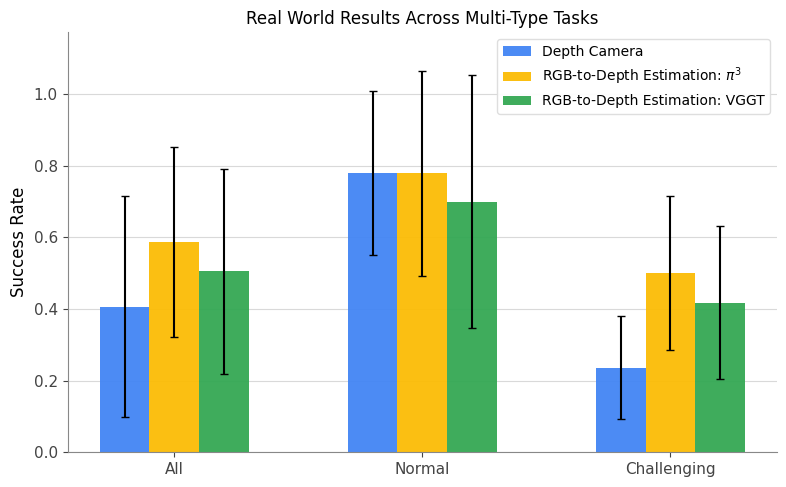

In [4]:

# --------------------
# Style to match the example
# --------------------
rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "legend.fontsize": 10,

    "axes.facecolor": "white",
    "figure.facecolor": "white",

    "axes.grid": True,
    "grid.color": "#d9d9d9",
    "grid.linestyle": "-",
    "grid.linewidth": 0.8,

    "axes.axisbelow": True,   # grid behind bars
})

# Muted (paper-friendly) Google-like colors
COLORS = {
    "Depth Camera":   "#4285F4",   # blue
    r"RGB-to-Depth Estimation: $\pi^3$":   "#FBBC05",   # yellow
    "RGB-to-Depth Estimation: VGGT":       "#34A853"    # green
}

# --------------------
# Data
# --------------------
groups = ["All", "Normal", "Challenging"]
methods = ["Depth Camera", r"RGB-to-Depth Estimation: $\pi^3$", "RGB-to-Depth Estimation: VGGT"]

avg = {
    "All": [0.40625, 0.5875, 0.50625],
    "Normal": [0.78, 0.78, 0.7],
    "Challenging": [0.2363636364, 0.5, 0.4181818182]
}
std = {
    "All": [0.3086934834, 0.2655183609, 0.2862836589],
    "Normal": [0.228035085, 0.2863564213, 0.3535533906],
    "Challenging": [0.1433368569, 0.2144761059, 0.2136266922]
}

# y-limit that won't clip error bars
max_y = max(avg[g][i] + std[g][i] for g in groups for i in range(3))

# --------------------
# Plot
# --------------------
x = np.arange(len(groups))
width = 0.2

fig, ax = plt.subplots(figsize=(8, 5))  # wide, short like the example

for i, method in enumerate(methods):
    # key = "pi3" if method == r"$\pi^3$" else method
    key = method
    ax.bar(
        x + (i - 1) * width,
        [avg[g][i] for g in groups],
        width=width,
        yerr=[std[g][i] for g in groups],
        capsize=3,
        color=COLORS[key],
        edgecolor="none",     # no heavy outlines (matches your example)
        alpha=0.95,
        label=method
    )

# Axes formatting
ax.set_ylabel("Success Rate")   # matches the example (change if you want)
ax.set_xticks(x)
ax.set_xticklabels(groups)

ax.set_ylim(0, max_y * 1.10)

# Spines: only left & bottom, light gray
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#888888")
ax.spines["bottom"].set_color("#888888")

# Ticks slightly gray
ax.tick_params(axis="both", colors="#444444")

# --- grid: horizontal only (paper style) ---
ax.grid(False)  # important: disables BOTH axes grids
ax.yaxis.grid(True, color="#d9d9d9", linewidth=0.8)
ax.xaxis.grid(False)
ax.set_axisbelow(True)
ax.set_title("Real World Results Across Multi-Type Tasks")

# Legend: framed, upper-right
leg = ax.legend(loc="upper right", frameon=True, fancybox=True, framealpha=0.95)
leg.get_frame().set_edgecolor("#dddddd")
leg.get_frame().set_linewidth(1.0)

plt.tight_layout()

# Save to current path
plt.savefig("real_world_result.png", dpi=300, bbox_inches="tight")
plt.show()

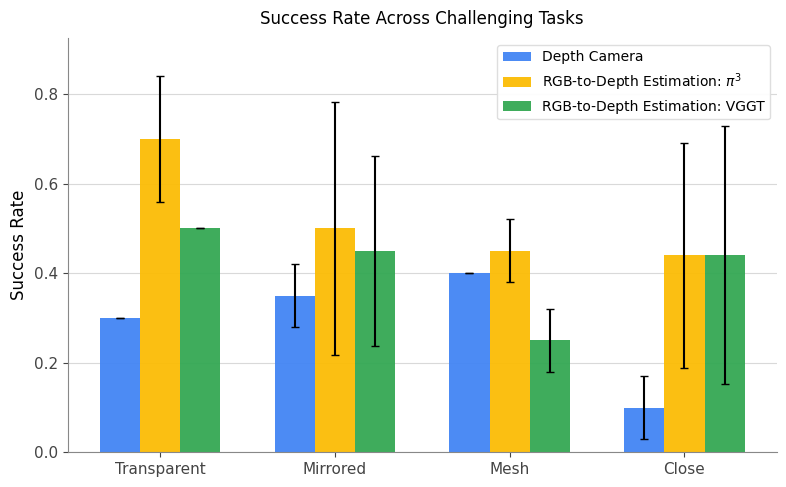

In [5]:
# --------------------
# Style (same as before)
# --------------------
rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "legend.fontsize": 10,
    "axes.facecolor": "white",
    "figure.facecolor": "white",
    "axes.axisbelow": True,
})

COLORS = {
    "Depth Camera":   "#4285F4",   # blue
    r"RGB-to-Depth Estimation: $\pi^3$":  "#FBBC05",   # yellow
    "RGB-to-Depth Estimation: VGGT": "#34A853"    # green
}

# --------------------
# Data
# --------------------
groups = ["Transparent", "Mirrored", "Mesh", "Close"]
methods = ["Depth Camera", r"RGB-to-Depth Estimation: $\pi^3$", "RGB-to-Depth Estimation: VGGT"]

sr = {
    "Transparent": [0.3, 0.7, 0.5],
    "Mesh":        [0.4, 0.45, 0.25],
    "Mirrored":    [0.35, 0.5, 0.45],
    "Close":       [0.1, 0.44, 0.44],
}

std = {
    "Transparent": [0.0, 0.1414213562, 0.0],
    "Mesh":        [0.0, 0.07071067812, 0.07071067812],
    "Mirrored":    [0.07071067812, 0.2828427125, 0.2121320344],
    "Close":       [0.07071067812, 0.250998008, 0.2880972058],
}

# y-limit that won't clip error bars
max_y = max(sr[g][i] + std[g][i] for g in groups for i in range(3))

# --------------------
# Plot
# --------------------
x = np.arange(len(groups))
width = 0.23

# fig, ax = plt.subplots(figsize=(9.0, 3.5))
fig, ax = plt.subplots(figsize=(8.0, 5))

for i, method in enumerate(methods):
    key = method
    ax.bar(
        x + (i - 1) * width,
        [sr[g][i] for g in groups],
        width=width,
        yerr=[std[g][i] for g in groups],
        capsize=3,
        color=COLORS[key],
        edgecolor="none",
        alpha=0.95,
        label=method
    )

# Labels / title
ax.set_ylabel("Success Rate")
ax.set_title("Success Rate Across Challenging Tasks", pad=10)

# X ticks
ax.set_xticks(x)
ax.set_xticklabels(groups)

# Y range
ax.set_ylim(0, max_y * 1.10)

# Grid: horizontal only (removes the vertical grey sticks)
ax.grid(False)
ax.yaxis.grid(True, color="#d9d9d9", linewidth=0.8)
ax.xaxis.grid(False)

# Spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#888888")
ax.spines["bottom"].set_color("#888888")
ax.tick_params(axis="both", colors="#444444")

# Legend (top-right box)
leg = ax.legend(loc="upper right", frameon=True, fancybox=True, framealpha=0.95)
leg.get_frame().set_edgecolor("#dddddd")
leg.get_frame().set_linewidth(1.0)

plt.tight_layout()

# Save to current path
plt.savefig("challenging_tasks.png", dpi=300, bbox_inches="tight")
plt.show()
